In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# This file needs latin-1 encoding, otherwise Pandas throws a decode error
df = pd.read_csv("../data/spam.csv", encoding="latin-1")

# Keep only the two useful columns and give them readable names
df = df[["v1", "v2"]]
df.columns = ["label", "message"]

print(df.shape)
print(df.head())
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

(5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
label      0
message    0
dtype: int64
Duplicates: 403


In [2]:
# Remove duplicate messages so the same text can't appear in both train and test later
df = df.drop_duplicates().reset_index(drop=True)

# Convert labels to numbers: ham = 0, spam = 1
df["target"] = df["label"].map({"ham": 0, "spam": 1})

# How imbalanced is the data?
print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True))

label
ham     4516
spam     653
Name: count, dtype: int64
label
ham     0.87367
spam    0.12633
Name: proportion, dtype: float64


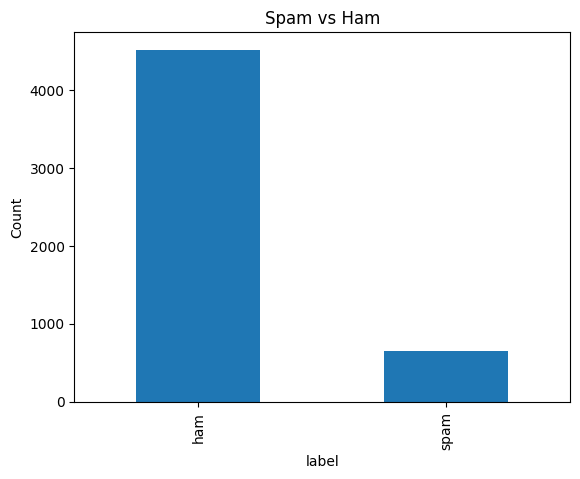

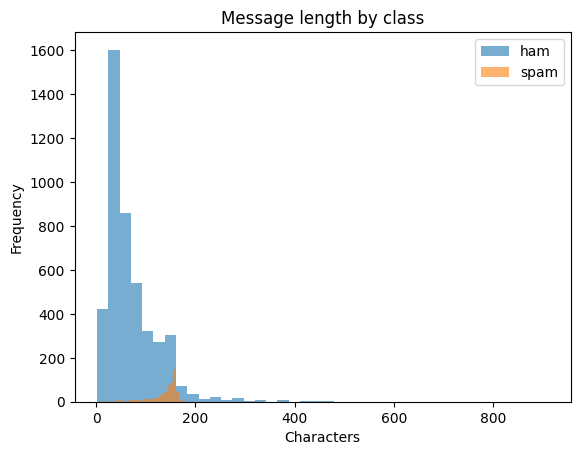

       char_count  word_count
label                        
ham     70.459256   14.134632
spam   137.891271   23.681470


In [3]:
# Message length, in characters and words
df["char_count"] = df["message"].apply(len)
df["word_count"] = df["message"].apply(lambda x: len(x.split()))

# Chart 1: class distribution
df["label"].value_counts().plot(kind="bar")
plt.title("Spam vs Ham")
plt.ylabel("Count")
plt.show()

# Chart 2: do spam messages tend to be longer?
df[df["target"] == 0]["char_count"].plot(kind="hist", bins=40, alpha=0.6, label="ham")
df[df["target"] == 1]["char_count"].plot(kind="hist", bins=40, alpha=0.6, label="spam")
plt.legend()
plt.title("Message length by class")
plt.xlabel("Characters")
plt.show()

print(df.groupby("label")[["char_count", "word_count"]].mean())